# Statistical inference in Python
**Foundations of Computational Social Science · TU Graz**

In this notebook you work through the lecture in five parts. Wherever you see `___`, replace it with your own code or answer. Cells marked **✎ Your turn** are the ones to complete.

Datasets (both simulated for this course):
- `course_grades.csv`: 40 students of one course, hours studied per week and exam grade (0–100).
- `university_grades.csv`: 20,000 students, with hours studied, attendance (%), age, prior knowledge (0–10) and exam grade.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

plt.rcParams["figure.figsize"] = (6, 4)
RED = "#E4154B"

## Part 1 · Revise the basics

In [2]:
course = pd.read_csv("data/course_grades.csv")
course.head()

,student_id,hours_studied,exam_grade
0,1,9.9,71.0
1,2,14.9,94.0
2,3,2.4,54.0
3,4,8.1,60.0
4,5,6.6,41.0


**✎ Your turn.** Compute the mean, standard deviation, variance, minimum and maximum of `exam_grade`.
Check: is the variance the standard deviation squared?

In [3]:
mean_grade = course["exam_grade"].mean()
sd_grade = course["exam_grade"].std()
var_grade = course["exam_grade"].var()
min_grade = course["exam_grade"].min()
max_grade = course["exam_grade"].max()
print(f"mean = {mean_grade:.2f}, sd = {sd_grade:.2f}, variance = {var_grade:.2f}")
print(f"min = {min_grade}, max = {max_grade}")

mean = 63.62, sd = 16.37, variance = 268.09
min = 8.0, max = 94.0


**✎ Your turn.** Plot a histogram of `exam_grade`. Where are most students? Does any grade stand out?

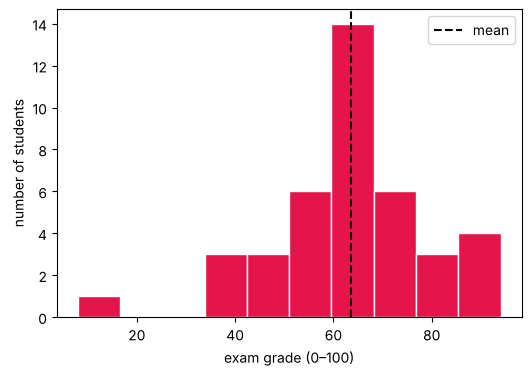

In [4]:
plt.hist(course["exam_grade"], bins=10, color=RED, edgecolor="white")
plt.axvline(mean_grade, color="black", linestyle="--", label="mean")
plt.xlabel("exam grade (0–100)")
plt.ylabel("number of students")
plt.legend()
plt.show()

## Part 2 · Null hypothesis significance testing

**✎ Your turn.** Before looking at the data, write down your hypotheses and your significance level.

- H0: ___
- H1: ___
- α = ___ (why this value?)

In [5]:
alpha = 0.05

## Part 3 · Correlation: hours studied and exam grade

### 3a · Scatter plot and correlation
**✎ Your turn.** Draw a scatter plot of `hours_studied` (x) against `exam_grade` (y). Does anything look unusual?

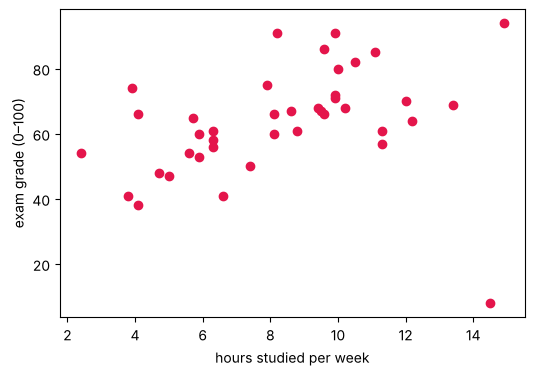

In [6]:
plt.scatter(course["hours_studied"], course["exam_grade"], color=RED)
plt.xlabel("hours studied per week")
plt.ylabel("exam grade (0–100)")
plt.show()

**✎ Your turn.** Compute Pearson's r and its p-value with `stats.pearsonr`. Is the association significant at your α?

In [7]:
r, p = stats.pearsonr(course["hours_studied"], course["exam_grade"])
print(f"r = {r:.2f}, p = {p:.3f}, significant: {p < alpha}")

r = 0.30, p = 0.062, significant: False


### 3b · The outlier
**✎ Your turn.** Find the student who doesn't fit the pattern (hint: many hours, very low grade).

In [8]:
course.sort_values("exam_grade").head(3)

,student_id,hours_studied,exam_grade
39,40,14.5,8.0
25,26,4.1,38.0
12,13,3.8,41.0


Student 40 studied 14.5 hours a week but scored 8 points: they were ill on the exam day.

**✎ Your turn.** Remove this student and compute r and p again. What changes? Is removing them justified, and would you decide this *before* or *after* seeing the result?

In [9]:
course_clean = course[course["student_id"] != 40]
r2, p2 = stats.pearsonr(course_clean["hours_studied"], course_clean["exam_grade"])
print(f"without outlier: r = {r2:.2f}, p = {p2:.6f}")

without outlier: r = 0.61, p = 0.000042


## Part 4 · Fitting a multiple linear regression

In [10]:
uni = pd.read_csv("data/university_grades.csv")
uni.describe().round(1)

,student_id,hours_studied,attendance,age,prior_knowledge,exam_grade
count,20000.0,20000.0,20000.0,20000.0,20000.0,20000.0
mean,10000.5,8.0,75.0,23.0,5.0,63.2
std,5773.6,3.0,11.8,3.4,2.0,13.7
min,1.0,0.0,21.0,18.0,0.0,12.3
25%,5000.8,6.0,67.0,21.0,4.0,53.9
50%,10000.5,8.0,75.0,22.0,5.0,63.2
75%,15000.2,10.0,83.0,25.0,6.0,72.5
max,20000.0,19.3,100.0,45.0,10.0,100.0


### 4a · Fit the model
**✎ Your turn.** Fit exam grade on hours studied, attendance and age:

exam_grade = b0 + b1·hours_studied + b2·attendance + b3·age + e

In [11]:
model = smf.ols("exam_grade ~ hours_studied + attendance + age", data=uni).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             exam_grade   R-squared:                       0.531
Model:                            OLS   Adj. R-squared:                  0.531
Method:                 Least Squares   F-statistic:                     7545.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        08:27:55   Log-Likelihood:                -73167.
No. Observations:               20000   AIC:                         1.463e+05
Df Residuals:                   19996   BIC:                         1.464e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        18.6762      0.614     30.407

### 4b · Read the output
**✎ Your turn.**
1. Write down the fitted equation.
2. Which predictors are significant at your α?
3. Interpret the coefficient of `hours_studied` in one sentence, starting with "Holding attendance and age constant, …".

### 4c · Model fit and prediction
**✎ Your turn.** What is R², and what does it mean here? (It is in the output above, or `model.rsquared`.)

Then use the model to predict the grade of a 22-year-old who studies 10 hours a week and attends 80% of classes. Then check by plugging the numbers into the equation by hand.

In [12]:
new_student = pd.DataFrame({"hours_studied": [10], "attendance": [80], "age": [22]})
model.predict(new_student)

0    69.935276
dtype: float64

In [13]:
b = model.params
by_hand = b["Intercept"] + b["hours_studied"] * 10 + b["attendance"] * 80 + b["age"] * 22
by_hand

np.float64(69.93527609910828)

## Part 5 · Issues: significance, sample size and other pitfalls

### 5a · Significant, but meaningful?
**✎ Your turn.** `age` is highly significant. How many points does being 10 years older add to the predicted grade? Is that meaningful?

In [14]:
model.params["age"] * 10

np.float64(0.936479895307538)

### 5b · Sample size
**✎ Your turn.** Fit the same model on a random sample of 100 students. Is age still significant? Why does the answer change?

In [15]:
small_sample = uni.sample(n=100, random_state=1)
model_small = smf.ols("exam_grade ~ hours_studied + attendance + age", data=small_sample).fit()
model_small.pvalues.round(4)

Intercept        0.0348
hours_studied    0.0000
attendance       0.0000
age              0.8265
dtype: float64

### 5c · An unobserved variable
Students with more prior knowledge also tend to study more. **✎ Your turn.** Add `prior_knowledge` to the model. What happens to the coefficient of `hours_studied`?

In [16]:
model_prior = smf.ols("exam_grade ~ hours_studied + attendance + age + prior_knowledge", data=uni).fit()
print(f"hours without prior knowledge: {model.params['hours_studied']:.2f}")
print(f"hours with prior knowledge:    {model_prior.params['hours_studied']:.2f}")

hours without prior knowledge: 2.77
hours with prior knowledge:    2.44


### 5d · Checking assumptions
Residuals against fitted values: for a good linear model the cloud should have no pattern and a constant spread (homoscedasticity).

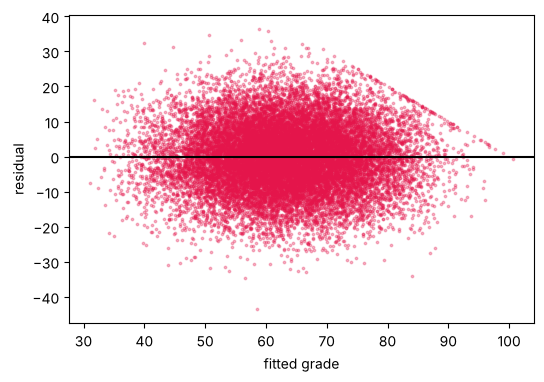

In [17]:
plt.scatter(model.fittedvalues, model.resid, s=3, alpha=0.3, color=RED)
plt.axhline(0, color="black")
plt.xlabel("fitted grade")
plt.ylabel("residual")
plt.show()

Q-Q plot of the residuals: if they are roughly normal, the points follow the line.

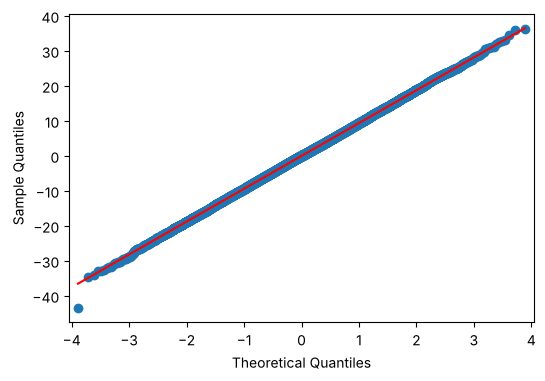

In [18]:
import statsmodels.api as sm
sm.qqplot(model.resid, line="s")
plt.show()

Correlation between the predictors (multicollinearity). **✎ Your turn.** Are any predictors very highly correlated (say above 0.8)?

In [19]:
uni[["hours_studied", "attendance", "age", "prior_knowledge"]].corr().round(2)

,hours_studied,attendance,age,prior_knowledge
hours_studied,1.00,0.41,0.01,0.35
attendance,0.41,1.00,0.01,0.19
age,0.01,0.01,1.00,0.00
prior_knowledge,0.35,0.19,0.00,1.00


### 5e · p-hacking in 10 lines
We create 20 variables of pure random noise and test each one against the exam grades of the 40 course students. None of them has any real relation to the grade.

**✎ Your turn.** Run the cell a few times with different seeds. How many "significant" results do you get on average? Why?

In [20]:
rng = np.random.default_rng(3)
significant = 0
for i in range(20):
    noise = rng.normal(size=len(course))
    r_noise, p_noise = stats.pearsonr(noise, course["exam_grade"])
    if p_noise < 0.05:
        significant += 1
print(f"{significant} of 20 pure-noise variables are 'significant' at p < .05")

4 of 20 pure-noise variables are 'significant' at p < .05


**Reflection.** In this notebook you made several decisions: your α, whether to drop student 40, which predictors to include. Which of them could change the conclusion? How could you make them transparent to others?